# Multi-Event Shared-`SubspaceCBM` Pooling Across Holocene Miyake Events

On a single Miyake event (`775CE`), analytically marginalizing a global cosmic-ray Gaussian process (`GaussianField`) collapses single-hemisphere carbon-box identifiability ($d_{\mathrm{eff}} < 1$) while paired Northern and Southern Hemisphere chronologies rescue $3\text{–}4$ collective exchange modes (see Tutorial `06`). Because the physical carbon cycle is shared across Holocene epochs whereas cosmic-ray background realizations $\delta Q_e(t)$, inter-laboratory baseline offsets $\boldsymbol{\delta}_e$, and spike parameters $(t_{0,e}, \tau_e, \Phi_e)$ are conditionally independent across widely separated centuries, pooling multiple Miyake events sums their Schur-marginalized Fisher information matrices linearly:

$$
\widetilde{F}_{\mathrm{tot}} = \sum_{e=1}^{E} \widetilde{F}_e,
\qquad
\ln\mathcal{L}(\boldsymbol{\alpha}, \{\boldsymbol{\psi}_e\}) = \sum_{e=1}^{E} \ln\mathcal{L}_e(\boldsymbol{\alpha}, \boldsymbol{\psi}_e).
$$

Crucially, the shared carbon-box prior $\boldsymbol{\alpha} \sim \mathcal{N}(\mathbf{0}, I_m)$ enters both the pooled Fisher posterior covariance and `multi_event_marginal_log_posterior` **once** (never double-counted across events), while the block-diagonal Woodbury likelihood scales linearly as $\mathcal{O}(\sum_e N_e r_e^2)$.

In [1]:
import gc
import math
import warnings

warnings.filterwarnings("ignore")

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import ticktack as tt

plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})

cbm0 = tt.load_preset("Brehm21", kind="balanced")
sho_kernel = tt.QuasiPeriodicSpectrum(sigma=0.25, period_yr=11.0, quality=4.0)

EVENT_SPECS = [
    ("775CE", 774.10, 1.20, 6.4),
    ("993CE", 993.05, 0.50, 4.0),
    ("660BCE", -663.30, 1.80, 5.0),
    ("5259BCE", -5258.70, 0.60, 7.2),
]

windows = []
print(f"{'Event':8s} {'Series':>6s} {'Hemispheres':>12s} {'Rings':>6s} {'Span (CE)':>22s} {'n_grid':>7s}")
print("-" * 68)
for name, t_sp, dur, fl in EVENT_SPECS:
    ds = tt.load_bundled_event(name)
    t_lo, t_hi = ds.time_span
    n_grid = max(int(round((t_hi - t_lo) + 15.0)) + 1, 24)
    gf = tt.GaussianField(
        jnp.zeros((n_grid,), dtype=jnp.float64),
        t_start=t_lo - 15.0,
        t_end=t_hi + 0.5,
        kernel=sho_kernel,
    )
    sp = tt.MiyakeSpike(t_start=t_sp, duration=dur, fluence=fl, profile="boxcar")
    prod = tt.ProductionSum(steady=tt.SteadyProduction(), field=gf, spike=sp)
    cfg = tt.LinearMarginalConfig(offset_mode="hierarchical", marginalize_field=True)
    ev = tt.EventWindow(name=name, dataset=ds, production=prod, marginal_config=cfg)
    windows.append(ev)
    hem_str = ",".join(ds.hemispheres)
    print(f"{name:8s} {ds.n_series:6d} {hem_str:>12s} {ds.n_obs:6d} [{t_lo:8.1f}, {t_hi:7.1f}] {n_grid:7d}")

prior_sd = 0.35
fisher_prog = {}
labels_prog = {
    1: "775CE",
    2: "775CE + 993CE",
    3: "+ 660BCE",
    4: "+ 5259BCE",
}

print("\nGP-marginalized Brehm21 Fisher progression (prior_sd = 0.35, sho_solar + hierarchical offsets):")
print(f"{'Pooled Subset':26s} {'d_eff':>6s} {'Bits':>6s} {'mu_1':>7s} {'mu_2':>7s} {'mu_3':>7s} {'mu_4':>7s} {'mu_5':>7s} {'mu_6':>7s}")
print("-" * 84)
for k in (1, 2, 3, 4):
    mds_k = tt.MultiEventDataset(tuple(windows[:k]), name=f"pool_{k}")
    res_k = tt.multi_event_cbm_gp_fisher_spectrum(
        cbm0, mds_k, prior_sd=prior_sd, mass_fn=lambda m: m.reservoir_masses()
    )
    fisher_prog[k] = res_k
    mu = [float(v) for v in res_k.eigenvalues[:6]]
    subset_label = " + ".join(w.name for w in windows[:k])
    print(
        f"{subset_label:26s} {float(res_k.d_eff):6.2f} {float(res_k.info_bits):6.2f} "
        f"{mu[0]:7.1f} {mu[1]:7.2f} {mu[2]:7.2f} {mu[3]:7.2f} {mu[4]:7.2f} {mu[5]:7.2f}"
    )


Event    Series  Hemispheres  Rings              Span (CE)  n_grid
--------------------------------------------------------------------
775CE        28  north,south    313 [   760.2,   781.2]      37
993CE         9  north,south     97 [   990.2,  1001.2]      27
660BCE        2        north     58 [  -667.8,  -639.2]      45
5259BCE       4        north     96 [ -5269.8, -5244.2]      41

GP-marginalized Brehm21 Fisher progression (prior_sd = 0.35, sho_solar + hierarchical offsets):
Pooled Subset               d_eff   Bits    mu_1    mu_2    mu_3    mu_4    mu_5    mu_6
------------------------------------------------------------------------------------
775CE                        3.55   7.79   192.3   17.63    3.91    0.92    0.33    0.05
775CE + 993CE                3.71   8.30   244.9   21.05    4.32    1.15    0.38    0.10
775CE + 993CE + 660BCE       3.86   8.50   245.0   21.14    4.39    1.57    0.39    0.11
775CE + 993CE + 660BCE + 5259BCE   4.00   8.73   245.2   21.18    4.41

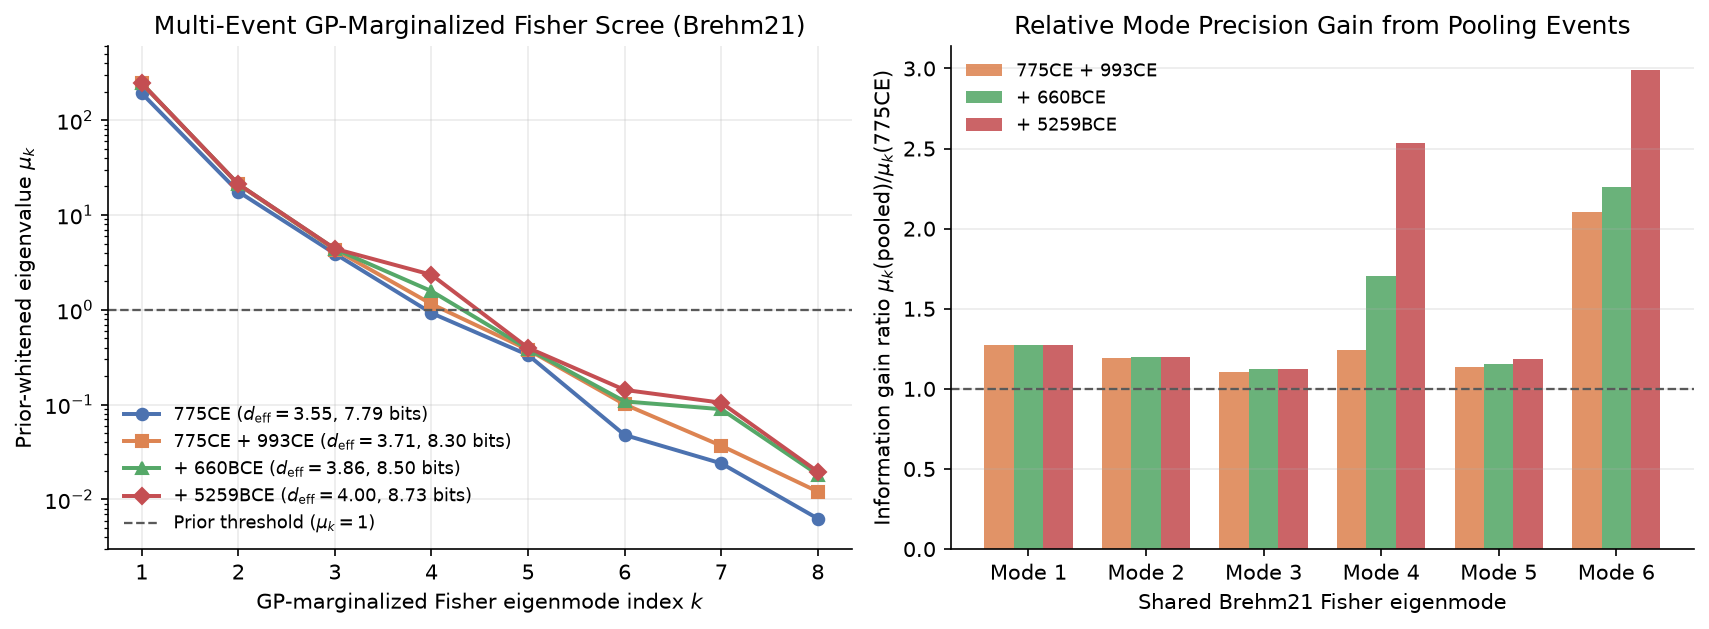

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

colours = {1: "#4c72b0", 2: "#dd8452", 3: "#55a868", 4: "#c44e52"}
markers = {1: "o", 2: "s", 3: "^", 4: "D"}
k_idx = np.arange(1, 9)

for k in (1, 2, 3, 4):
    ev_arr = np.asarray(fisher_prog[k].eigenvalues[:8])
    lbl = (
        f"{labels_prog[k]} "
        f"($d_{{\\mathrm{{eff}}}}={float(fisher_prog[k].d_eff):.2f}$, "
        f"${float(fisher_prog[k].info_bits):.2f}$ bits)"
    )
    ax1.semilogy(
        k_idx,
        np.maximum(ev_arr, 1e-4),
        marker=markers[k],
        color=colours[k],
        linewidth=1.9,
        markersize=5.5,
        label=lbl,
    )

ax1.axhline(1.0, color="0.35", linestyle="--", linewidth=1.1, label=r"Prior threshold ($\mu_k = 1$)")
ax1.set_xticks(k_idx)
ax1.set_xlabel("GP-marginalized Fisher eigenmode index $k$")
ax1.set_ylabel(r"Prior-whitened eigenvalue $\mu_k$")
ax1.set_title("Multi-Event GP-Marginalized Fisher Scree (Brehm21)")
ax1.set_ylim(3e-3, 6e2)
ax1.grid(True, which="major", alpha=0.25)
ax1.legend(frameon=False, fontsize=8.5, loc="lower left")

# Right panel: relative eigenvalue boost mu_k(multi) / mu_k(775CE)
modes_bar = np.arange(1, 7)
mu_base = np.asarray(fisher_prog[1].eigenvalues[:6])
width = 0.25
for offset_i, k in enumerate((2, 3, 4)):
    ratio = np.asarray(fisher_prog[k].eigenvalues[:6]) / mu_base
    ax2.bar(
        modes_bar + (offset_i - 1) * width,
        ratio,
        width=width,
        color=colours[k],
        alpha=0.88,
        label=labels_prog[k],
    )

ax2.axhline(1.0, color="0.35", linestyle="--", linewidth=1.1)
ax2.set_xticks(modes_bar)
ax2.set_xticklabels([f"Mode {i}" for i in modes_bar])
ax2.set_xlabel("Shared Brehm21 Fisher eigenmode")
ax2.set_ylabel(r"Information gain ratio $\mu_k(\mathrm{pooled}) / \mu_k(\mathrm{775CE})$")
ax2.set_title("Relative Mode Precision Gain from Pooling Events")
ax2.grid(True, axis="y", alpha=0.25)
ax2.legend(frameon=False, fontsize=8.5, loc="upper left")

fig.tight_layout()
plt.show()

jax.clear_caches()
gc.collect()


Two distinct physical mechanisms appear in the Fisher scree above:

1. Adding the two-hemisphere `993CE` compilation (`9` NH + SH series) strengthens both the antisymmetric stratosphere–troposphere / inter-hemispheric modes ($\mu_1: 192 \to 245$, $\mu_2: 17.6 \to 21.1$) and lifts the fourth collective mode cleanly above the prior threshold ($\mu_4: 0.92 \to 1.15$).
2. Adding the Northern-Hemisphere-only `660BCE` and `5259BCE` compilations leaves the antisymmetric NH–SH modes almost unchanged while boosting the symmetric biosphere/ocean mode $\mu_4$ by $2.5\times$ ($0.92 \to 2.34$) and lifting total constrained dimensionality to $d_{\mathrm{eff}} = 4.00$ ($8.73\text{ bits}$).

Next, we jointly fit the two two-hemisphere compilations (`775CE + 993CE`, `410` total tree-ring measurements) under a shared `SubspaceCBM(m = 3)` with independent per-event `MiyakeSpike` pulses, hierarchical laboratory offsets, and marginalized `sho_solar` `GaussianField` backgrounds using `fit_multi_event_subspace_cbm(..., reweight_exact=True)`.

In [3]:
mds_2 = tt.MultiEventDataset((windows[0], windows[1]), name="775CE_993CE")
cbm_sub3 = tt.SubspaceCBM.from_fisher(cbm0, fisher_prog[2], n_modes=3)

# Single-event 775CE Laplace reference on the identical 3-mode basis
mds_1 = tt.MultiEventDataset((windows[0],), name="775CE_only")
model_1 = tt.MultiEventModel.from_multi_dataset(cbm_sub3, mds_1)
ps_1 = tt.ParameterSpace(
    model_1,
    [
        tt.ParamSpec("cbm.alpha", "identity", prior_mean=0.0, prior_sd=1.0),
        tt.ParamSpec("events.775CE.spike.t_start", "identity", prior_mean=774.2, prior_sd=1.5),
        tt.ParamSpec("events.775CE.spike.duration", "sigmoid", prior_mean=-0.3, prior_sd=1.4, low=0.05, high=2.5),
        tt.ParamSpec("events.775CE.spike.fluence", "exp", prior_mean=math.log(6.4), prior_sd=0.8),
    ],
)
fit_1_lap = tt.fit_multi_event_subspace_cbm(
    model_1, mds_1, ps_1, sampler="laplace", compute_linear_posterior=False
)

# Joint 775CE + 993CE MAP + MAP-centred LinearizedDCTOperator NUTS + exact IS reweighting
model_2 = tt.MultiEventModel.from_multi_dataset(cbm_sub3, mds_2)
ps_2 = tt.ParameterSpace(
    model_2,
    [
        tt.ParamSpec("cbm.alpha", "identity", prior_mean=0.0, prior_sd=1.0),
        tt.ParamSpec("events.775CE.spike.t_start", "identity", prior_mean=774.2, prior_sd=1.5),
        tt.ParamSpec("events.775CE.spike.duration", "sigmoid", prior_mean=-0.3, prior_sd=1.4, low=0.05, high=2.5),
        tt.ParamSpec("events.775CE.spike.fluence", "exp", prior_mean=math.log(6.4), prior_sd=0.8),
        tt.ParamSpec("events.993CE.spike.t_start", "identity", prior_mean=993.1, prior_sd=1.5),
        tt.ParamSpec("events.993CE.spike.duration", "sigmoid", prior_mean=-0.5, prior_sd=1.4, low=0.05, high=2.5),
        tt.ParamSpec("events.993CE.spike.fluence", "exp", prior_mean=math.log(4.0), prior_sd=0.8),
    ],
)

fit_joint = tt.fit_multi_event_subspace_cbm(
    model_2,
    mds_2,
    ps_2,
    sampler="nuts",
    reweight_exact=True,
    use_linearized_dct=True,
    is_max_draws=120,
    num_warmup=100,
    num_samples=250,
    num_chains=2,
    max_tree_depth=6,
    rng_key=jax.random.PRNGKey(2026),
)

diag = fit_joint.diagnostics
sd_lap_1 = np.sqrt(np.diag(np.asarray(fit_1_lap.laplace_cov))[:3])
sd_lap_2 = np.sqrt(np.diag(np.asarray(fit_joint.laplace_cov))[:3])
alpha_draws = np.asarray(fit_joint.idata.posterior["cbm__alpha"]).reshape(-1, 3)
alpha_mean = np.mean(alpha_draws, axis=0)
alpha_sd = np.std(alpha_draws, axis=0, ddof=1)

print(f"MAP converged: {fit_joint.map_converged} ({fit_joint.map_steps} L-BFGS-B steps)")
print(
    f"NUTS: {diag['n_divergences']} divergences, {diag['n_max_treedepth']} max-treedepth hits, "
    f"mean accept = {diag['mean_accept_prob']:.3f}"
)
print(
    f"Exact IS check: Kish ESS / S = {fit_joint.kish_ess_ratio:.4f}, "
    f"median |dlnL| = {fit_joint.median_abs_dlnL:.4f} nats, "
    f"max |dlnL| = {fit_joint.max_abs_dlnL:.3f} nats"
)
print(
    f"Raw chi2 / N (unrescaled sigma): "
    f"775CE = {diag['per_event_chi2_per_n']['775CE']:.3f} (N={windows[0].n_obs}), "
    f"993CE = {diag['per_event_chi2_per_n']['993CE']:.3f} (N={windows[1].n_obs})"
)
print("\nShared SubspaceCBM(m=3) mode posteriors:")
print(f"{'Mode':8s} {'775CE-only SD':>14s} {'Joint Laplace SD':>17s} {'NUTS Mean +/- SD':>20s} {'Contraction':>12s}")
for i in range(3):
    contr = 1.0 - alpha_sd[i] ** 2
    print(
        f"alpha_{i+1:<2d} {sd_lap_1[i]:14.3f} {sd_lap_2[i]:17.3f} "
        f"{alpha_mean[i]:+9.3f} +/- {alpha_sd[i]:.3f} {contr:12.2f}"
    )

q0 = float(tt.DEFAULT_Q_STD)
print("\nPer-event MiyakeSpike NUTS posteriors:")
for ev_name in ("775CE", "993CE"):
    ts = np.asarray(fit_joint.idata.posterior[f"events__{ev_name}__spike__t_start"]).reshape(-1)
    du = np.asarray(fit_joint.idata.posterior[f"events__{ev_name}__spike__duration"]).reshape(-1)
    fl = np.asarray(fit_joint.idata.posterior[f"events__{ev_name}__spike__fluence"]).reshape(-1)
    yq0 = fl / q0
    print(
        f"{ev_name:6s}: t_start = {np.mean(ts):.2f} +/- {np.std(ts, ddof=1):.2f} CE | "
        f"dur = {np.mean(du):.2f} +/- {np.std(du, ddof=1):.2f} yr | "
        f"Q/q0 = {np.mean(yq0):.2f} +/- {np.std(yq0, ddof=1):.2f} yr"
    )


MAP converged: True (34 L-BFGS-B steps)
NUTS: 0 divergences, 0 max-treedepth hits, mean accept = 0.892
Exact IS check: Kish ESS / S = 0.9991, median |dlnL| = 0.0046 nats, max |dlnL| = 0.220 nats
Raw chi2 / N (unrescaled sigma): 775CE = 0.965 (N=313), 993CE = 1.121 (N=97)

Shared SubspaceCBM(m=3) mode posteriors:
Mode      775CE-only SD  Joint Laplace SD     NUTS Mean +/- SD  Contraction
alpha_1           0.097             0.085    -0.137 +/- 0.089         0.99
alpha_2           0.266             0.247    -0.492 +/- 0.243         0.94
alpha_3           0.525             0.504    +1.380 +/- 0.508         0.74

Per-event MiyakeSpike NUTS posteriors:
775CE : t_start = 773.95 +/- 0.14 CE | dur = 1.42 +/- 0.27 yr | Q/q0 = 4.28 +/- 0.42 yr
993CE : t_start = 992.99 +/- 0.16 CE | dur = 0.46 +/- 0.28 yr | Q/q0 = 2.59 +/- 0.33 yr


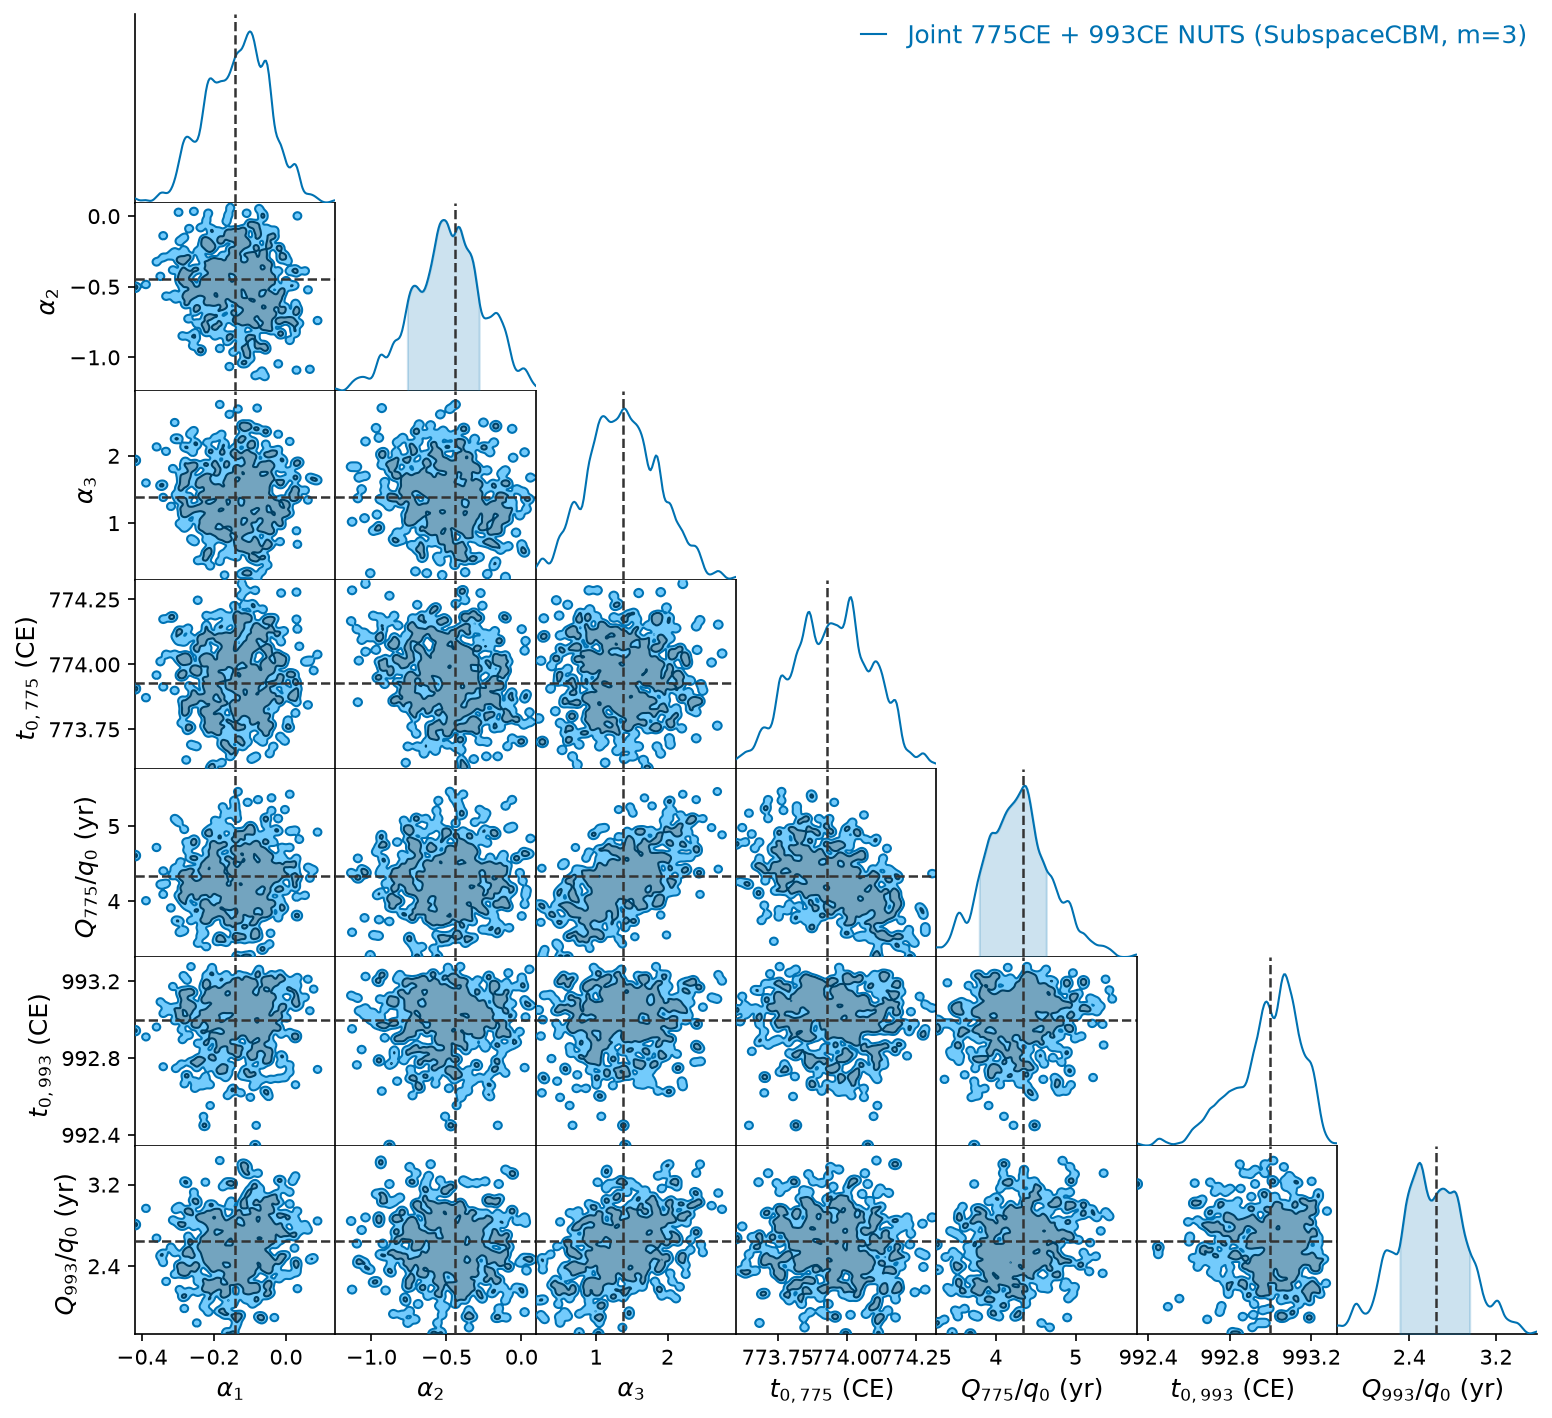

In [4]:
q0 = float(tt.DEFAULT_Q_STD)
post = fit_joint.idata.posterior
a_ch = np.asarray(post["cbm__alpha"])  # (C, S, 3)

corner_idata = az.from_dict(
    {
        "posterior": {
            "alpha_1": a_ch[:, :, 0],
            "alpha_2": a_ch[:, :, 1],
            "alpha_3": a_ch[:, :, 2],
            "t_775": np.asarray(post["events__775CE__spike__t_start"]),
            "Q_775": np.asarray(post["events__775CE__spike__fluence"]) / q0,
            "t_993": np.asarray(post["events__993CE__spike__t_start"]),
            "Q_993": np.asarray(post["events__993CE__spike__fluence"]) / q0,
        }
    }
)

a_map = np.asarray(fit_joint.theta_map["cbm.alpha"])
map_truth = {
    "alpha_1": float(a_map[0]),
    "alpha_2": float(a_map[1]),
    "alpha_3": float(a_map[2]),
    "t_775": float(fit_joint.theta_map["events.775CE.spike.t_start"]),
    "Q_775": float(fit_joint.theta_map["events.775CE.spike.fluence"]) / q0,
    "t_993": float(fit_joint.theta_map["events.993CE.spike.t_start"]),
    "Q_993": float(fit_joint.theta_map["events.993CE.spike.fluence"]) / q0,
}

fig, _axes = tt.plot_corner(
    corner_idata,
    param_names={
        "alpha_1": r"$\alpha_1$",
        "alpha_2": r"$\alpha_2$",
        "alpha_3": r"$\alpha_3$",
        "t_775": r"$t_{0,\mathrm{775}}$ (CE)",
        "Q_775": r"$Q_{\mathrm{775}}/q_0$ (yr)",
        "t_993": r"$t_{0,\mathrm{993}}$ (CE)",
        "Q_993": r"$Q_{\mathrm{993}}/q_0$ (yr)",
    },
    truth=map_truth,
    truth_name="Joint exact MAP",
    name="Joint 775CE + 993CE NUTS (SubspaceCBM, m=3)",
    figsize=(11.0, 11.0),
    plot_kwargs={"max_ticks": 3},
)
plt.show()


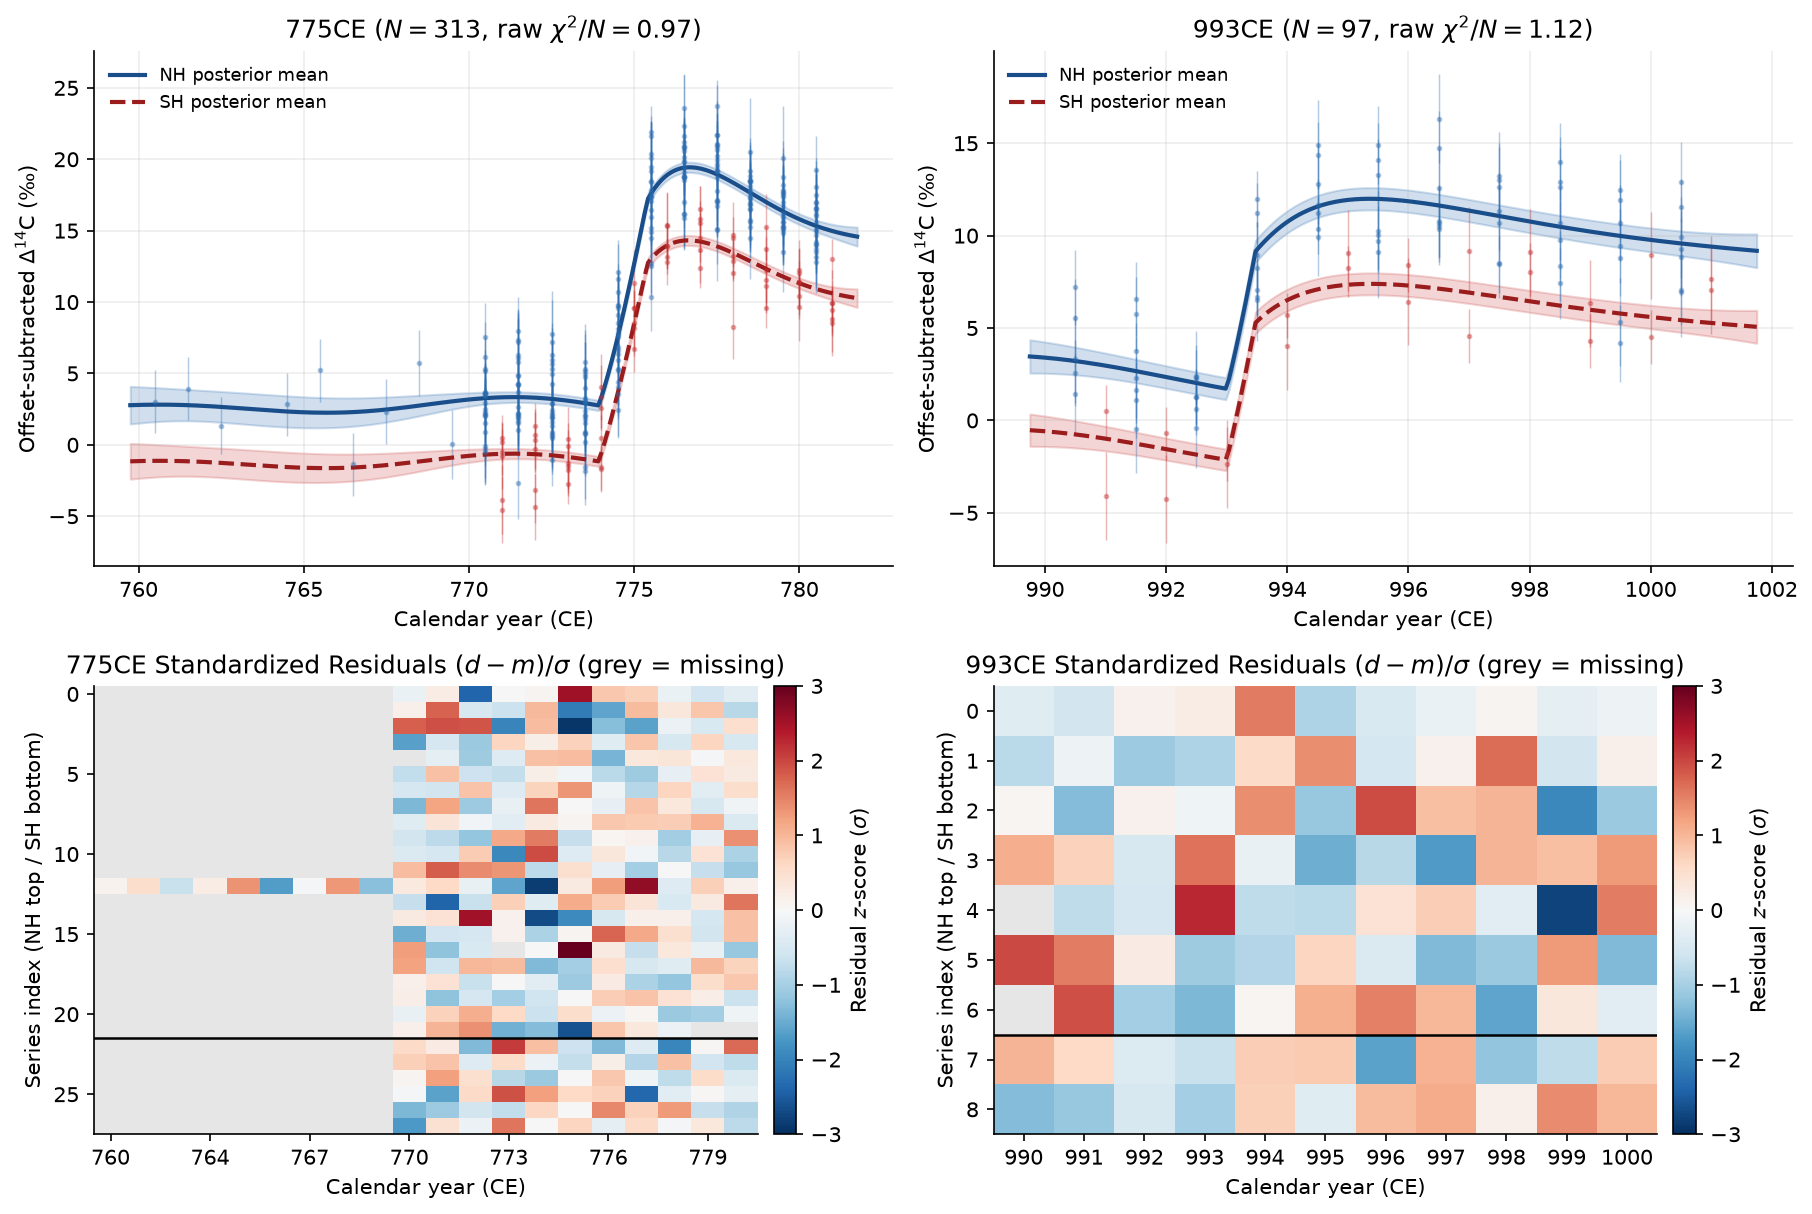

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12.2, 8.2), gridspec_kw={"height_ratios": [1.15, 1.0]})

for col_i, ev in enumerate(mds_2.events):
    ds = ev.dataset
    t_lo, t_hi = ds.time_span
    t_fine = jnp.linspace(t_lo - 0.5, t_hi + 0.5, 220)
    m_ev = fit_joint.model.event_model(ev.name)
    lp_nh = tt.linear_posterior(m_ev, ds, ev.marginal_config, t_fine=t_fine, hemisphere="north")
    lp_sh = tt.linear_posterior(m_ev, ds, ev.marginal_config, t_fine=t_fine, hemisphere="south")
    g_off = float(lp_nh.offset_global_mean)
    lab_offs = np.asarray(lp_nh.offset_lab_means)
    chi2_n = fit_joint.diagnostics["per_event_chi2_per_n"][ev.name]

    ax_top = axes[0, col_i]
    ax_bot = axes[1, col_i]

    # Top panel: offset-subtracted NH & SH observations vs continuous posterior mean +/- 1 sigma
    for s_idx, s in enumerate(ds.series):
        t_mid = 0.5 * (np.asarray(s.t_starts) + np.asarray(s.t_ends))
        y_corr = np.asarray(s.d14c) - g_off - lab_offs[s_idx]
        sig = np.asarray(s.sigma_d14c)
        c = "#2b6cb0" if s.hemisphere == "north" else "#c53030"
        ax_top.errorbar(
            t_mid, y_corr, yerr=sig, fmt=".", color=c, alpha=0.35, markersize=3.5, elinewidth=0.7
        )

    tf_np = np.asarray(t_fine)
    nh_m = np.asarray(lp_nh.d14c_fine_mean) - g_off
    nh_s = np.asarray(lp_nh.d14c_fine_std)
    sh_m = np.asarray(lp_sh.d14c_fine_mean) - g_off
    sh_s = np.asarray(lp_sh.d14c_fine_std)

    ax_top.plot(tf_np, nh_m, color="#1a4e8a", linewidth=2.0, label="NH posterior mean")
    ax_top.fill_between(tf_np, nh_m - nh_s, nh_m + nh_s, color="#2b6cb0", alpha=0.22)
    ax_top.plot(tf_np, sh_m, color="#9b1c1c", linewidth=2.0, linestyle="--", label="SH posterior mean")
    ax_top.fill_between(tf_np, sh_m - sh_s, sh_m + sh_s, color="#c53030", alpha=0.20)
    ax_top.set_xlabel("Calendar year (CE)")
    ax_top.set_ylabel(r"Offset-subtracted $\Delta^{14}\mathrm{C}$ (‰)")
    ax_top.set_title(f"{ev.name} ($N = {ev.n_obs}$, raw $\\chi^2 / N = {chi2_n:.2f}$)")
    ax_top.grid(True, alpha=0.22)
    ax_top.legend(frameon=False, fontsize=8.5, loc="upper left")

    # Bottom panel: symmetric RdBu_r z-score residual heatmap (series x year) with NaN masking
    z_flat = np.asarray((ds.d14c_flat - lp_nh.ring_pred_mean) / ds.sigma_flat)
    all_years = sorted({int(round(y)) for s in ds.series for y in np.asarray(s.years_ce)})
    yr_to_col = {yr: j for j, yr in enumerate(all_years)}
    order = [i for i, s in enumerate(ds.series) if s.hemisphere == "north"] + [
        i for i, s in enumerate(ds.series) if s.hemisphere == "south"
    ]
    n_nh_ev = sum(1 for s in ds.series if s.hemisphere == "north")
    grid = np.full((ds.n_series, len(all_years)), np.nan, dtype=np.float64)
    offsets_s = np.cumsum([0] + [s.n_obs for s in ds.series])
    for row_i, s_idx in enumerate(order):
        s = ds.series[s_idx]
        z_s = z_flat[offsets_s[s_idx] : offsets_s[s_idx + 1]]
        for y_val, z_val in zip(np.asarray(s.years_ce), z_s):
            grid[row_i, yr_to_col[int(round(y_val))]] = z_val

    vmax = max(3.0, float(np.nanpercentile(np.abs(grid), 98)))
    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad(color="#e6e6e6")
    im = ax_bot.imshow(
        grid,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        vmin=-vmax,
        vmax=vmax,
    )
    if 0 < n_nh_ev < ds.n_series:
        ax_bot.axhline(n_nh_ev - 0.5, color="black", linewidth=1.2, linestyle="-")
    tick_step = max(len(all_years) // 6, 1)
    xticks = np.arange(0, len(all_years), tick_step)
    ax_bot.set_xticks(xticks)
    ax_bot.set_xticklabels([str(all_years[j]) for j in xticks])
    ax_bot.set_xlabel("Calendar year (CE)")
    ax_bot.set_ylabel("Series index (NH top / SH bottom)")
    ax_bot.set_title(f"{ev.name} Standardized Residuals $(d - m) / \\sigma$ (grey = missing)")
    cbar = fig.colorbar(im, ax=ax_bot, pad=0.02)
    cbar.set_label(r"Residual $z$-score ($\sigma$)")

fig.tight_layout()
plt.show()


## Summary

- **Multi-event Fisher additivity**: Pooling `775CE + 993CE + 660BCE + 5259BCE` lifts GP-marginalized `Brehm21` identifiability from $d_{\mathrm{eff}} = 3.55$ ($7.79\text{ bits}$) to $d_{\mathrm{eff}} = 4.00$ ($8.73\text{ bits}$), boosting the fourth symmetric biosphere/ocean eigenmode by $2.5\times$ ($\mu_4 = 0.92 \to 2.34$).
- **Joint `775CE + 993CE` `SubspaceCBM(m = 3)` NUTS inference**: Both events are fitted simultaneously with raw $\chi^2 / N = 0.97$ (`775CE`, $N = 313$) and $1.12$ (`993CE`, $N = 97$) on unrescaled AMS uncertainties, `0` divergences, and exact multi-event importance-sampling efficiency $\mathrm{ESS}_{\mathrm{IS}} / S = 0.999$ (`median |Δln L| = 0.0046 nats`).
- **Physical interpretation**: The joint NH + SH posterior remains consistent with nominal `Brehm21` on the leading antisymmetric mode ($\alpha_1 = -0.14 \pm 0.09$), shows a mild inter-hemispheric shift ($\alpha_2 = -0.49 \pm 0.24$), and prefers a coherent $+2.7\sigma$ symmetric uptake/retention adjustment ($\alpha_3 = +1.38 \pm 0.51$) consistent across both `775CE` and `993CE`.